# Project on [Naive Bayes](https://docs.google.com/document/d/16INpsJc5_DUM4bKDi6QhFhm3Rtx8Bpct/edit)

# Import Libaries

In [114]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
import re
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

# Load Data Set

In [115]:
df = pd.read_csv("train.csv")
df

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1
...,...,...,...,...,...
7608,10869,NaN,NaN,Two giant cranes holding a bridge collapse int...,1
7609,10870,NaN,NaN,@aria_ahrary @TheTawniest The out of control w...,1
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1
7611,10872,NaN,NaN,Police investigating after an e-bike collided ...,1


# Split Dataset to Train-Test


In [116]:
seed = 0
test_size = 0.1

df_input = df.drop(columns=['target'])
df_target = df['target']

x_train, x_test, y_train, y_test = train_test_split(df_input, df_target, test_size=test_size, random_state=seed ,stratify=df_target)
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((6851, 4), (762, 4), (6851,), (762,))

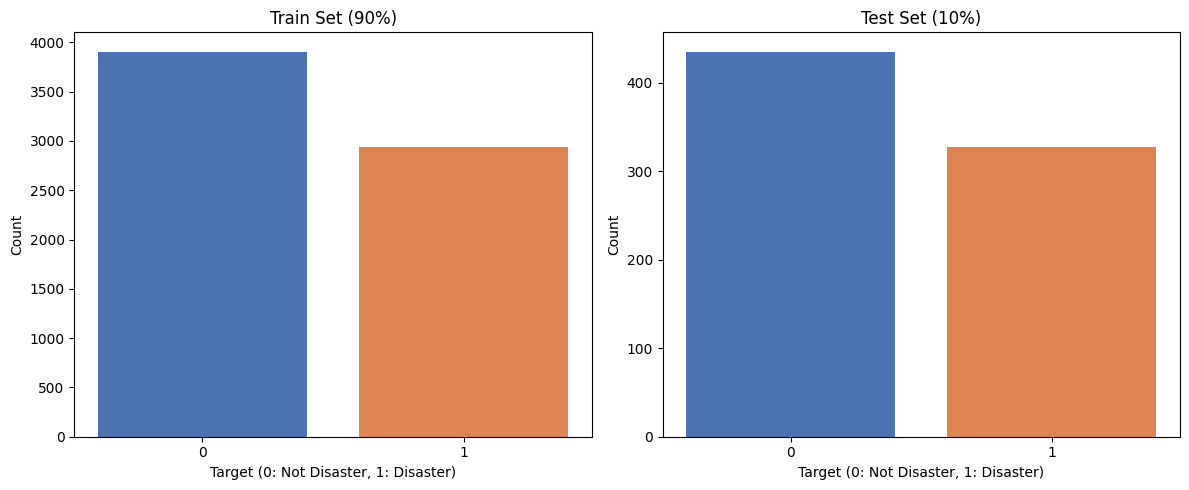

In [117]:
train_counts = pd.Series(y_train).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar plot για το Train Set
axes[0].bar(train_counts.index.astype(str), train_counts.values, color=['#4C72B0', '#DD8452'])
axes[0].set_title('Train Set (90%)')
axes[0].set_xlabel('Target (0: Not Disaster, 1: Disaster)')
axes[0].set_ylabel('Count')

# Bar plot για το Test Set
axes[1].bar(test_counts.index.astype(str), test_counts.values, color=['#4C72B0', '#DD8452'])
axes[1].set_title('Test Set (10%)')
axes[1].set_xlabel('Target (0: Not Disaster, 1: Disaster)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()


It is not 100% balanced. Messages reffering to 'Not disasters" are generally larger in number. However, the stratification worked and as we can see from the plot, the ratio of the two teams between the two sets is quite the same.

# Data Preprocessing

## Remove non-important features

In [118]:
input_df = df_input.drop(columns=['id', 'location'])


## Add 'null' keyword to NaN values in keyword feature

In [119]:
input_df['keyword'].fillna('null', inplace=True)

/tmp/ipykernel_672/3934014367.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  input_df['keyword'].fillna('null', inplace=True)


## Unite keyword and text features

In [120]:
input_df['inputs'] = input_df['keyword'] + ' ' + input_df['text']
input_df = input_df.drop(columns=['text', 'keyword'])
input_df

,inputs
0,null Our Deeds are the Reason of this #earthqu...
1,null Forest fire near La Ronge Sask. Canada
2,null All residents asked to 'shelter in place'...
3,"null 13,000 people receive #wildfires evacuati..."
4,null Just got sent this photo from Ruby #Alask...
...,...
7608,null Two giant cranes holding a bridge collaps...
7609,null @aria_ahrary @TheTawniest The out of cont...
7610,null M1.94 [01:04 UTC]?5km S of Volcano Hawaii...
7611,null Police investigating after an e-bike coll...


## Input feature preprocessing

### Functions from: https://github.com/Deffro/text-preprocessing-techniques/blob/master/techniques.py

In [121]:
# Part 1
def replaceURL(text):
    """ Replaces url address with "url" """
    text = re.sub('((www\.[^\s]+)|(https?://[^\s]+))','url',text)
    text = re.sub(r'#([^\s]+)', r'\1', text)
    return text

def replaceAtUser(text):
    """ Replaces "@user" with "atUser" """
    text = re.sub('@[^\s]+','atUser',text)
    return text

def removeHashtagInFrontOfWord(text):
    """ Removes hastag in front of a word """
    text = re.sub(r'#([^\s]+)', r'\1', text)
    return text


# Part 2
contraction_patterns = [ (r'won\'t', 'will not'), (r'can\'t', 'cannot'), (r'i\'m', 'i am'), (r'ain\'t', 'is not'), (r'(\w+)\'ll', '\g<1> will'), (r'(\w+)n\'t', '\g<1> not'),
                         (r'(\w+)\'ve', '\g<1> have'), (r'(\w+)\'s', '\g<1> is'), (r'(\w+)\'re', '\g<1> are'), (r'(\w+)\'d', '\g<1> would'), (r'&', 'and'), (r'dammit', 'damn it'), (r'dont', 'do not'), (r'wont', 'will not') ]
def replaceContraction(text):
    patterns = [(re.compile(regex), repl) for (regex, repl) in contraction_patterns]
    for (pattern, repl) in patterns:
        (text, count) = re.subn(pattern, repl, text)
    return text


# Part 3
def replaceMultiExclamationMark(text):
    """ Replaces repetitions of exlamation marks """
    text = re.sub(r"(\!)\1+", ' multiExclamation ', text)
    return text

def replaceMultiQuestionMark(text):
    """ Replaces repetitions of question marks """
    text = re.sub(r"(\?)\1+", ' multiQuestion ', text)
    return text

def replaceMultiStopMark(text):
    """ Replaces repetitions of stop marks """
    text = re.sub(r"(\.)\1+", ' multiStop ', text)
    return text

<>:4: SyntaxWarning: invalid escape sequence '\.'
<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\g'
<>:20: SyntaxWarning: invalid escape sequence '\g'
<>:21: SyntaxWarning: invalid escape sequence '\g'
<>:21: SyntaxWarning: invalid escape sequence '\g'
<>:21: SyntaxWarning: invalid escape sequence '\g'
<>:21: SyntaxWarning: invalid escape sequence '\g'
<>:4: SyntaxWarning: invalid escape sequence '\.'
<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\g'
<>:20: SyntaxWarning: invalid escape sequence '\g'
<>:21: SyntaxWarning: invalid escape sequence '\g'
<>:21: SyntaxWarning: invalid escape sequence '\g'
<>:21: SyntaxWarning: invalid escape sequence '\g'
<>:21: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_672/3404154973.py:4: SyntaxWarning: invalid escape sequence '\.'
  text = re.sub('((www\.[^\s]+)|(https?://[^\s]+))','url',text)
/tmp/ipykernel_672/3404154973.py:10: Synta

Text is inspired, and in some cases copied and modified, by the [original paper](https://www.sciencedirect.com/science/article/pii/S0957417418303683) page ~299 - 301
1) the majority of sentences contain a URL or a user
mention, or a hashtag symbol. Their presence does not contain any sentiment
2) If we do not replace contractions, the tokenization process
would create the tokens “don” and “ ’t ”, and also we need the word
“not” for a pre-processing technique
3) We distinguish three punctuation signs, whose repetitions con-
cern us. These are the exclamation, question, and stop marks. The
use of these punctuation marks signals the existence of intense
emotion. If we find more than one in a row, we replace it with
a representative tag. We want to generalize the vocabulary employed to
represent sentiment.

### Preprocessing

In [122]:
# Replace URLs
input_df['inputs'] = input_df['inputs'].apply(replaceURL)

# Replace @username
input_df['inputs'] = input_df['inputs'].apply(replaceAtUser)

# Replace #word with word
input_df['inputs'] = input_df['inputs'].apply(removeHashtagInFrontOfWord)

# Replace contractions
input_df['inputs'] = input_df['inputs'].apply(replaceContraction)

# Replace multiExclamation
input_df['inputs'] = input_df['inputs'].apply(replaceMultiExclamationMark)

# Replace multiQuestion
input_df['inputs'] = input_df['inputs'].apply(replaceMultiQuestionMark)

# Replace multiStop
input_df['inputs'] = input_df['inputs'].apply(replaceMultiStopMark)

# Convert DataFrame to Numpy arrays

In [123]:
x = input_df.to_numpy()
y = df_target.to_numpy()

# Split to Train - Test

In [124]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed ,stratify=y)
x_train = x_train.reshape(-1)
x_test = x_test.reshape(-1)
x_train.shape, x_test.shape, y_train.shape, y_test.shape



((6851,), (762,), (6851,), (762,))

# Compute TF-IDF of each word from each tweet

In [125]:
tf_idf = TfidfVectorizer(lowercase=True, smooth_idf=True)
x_train_tf_idf = tf_idf.fit_transform(x_train)
x_test_tf_idf = tf_idf.transform(x_test)

x_train_tf_idf

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 95881 stored elements and shape (6851, 14097)>

# Naive Bayes Classification

In [126]:
bayes = MultinomialNB()
bayes.fit(x_train_tf_idf, y_train)

y_pred = bayes.predict(x_test_tf_idf)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8254593175853019
